# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Сєров Єгор
**Група:** 3-10
**Дата:** 13.11.26

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Фіксація генераторів випадкових чисел для відтворюваності результатів
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантаження набору даних Fashion MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Перелік назв 10 класів Fashion MNIST (від 0 до 9)
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Виведення розмірів (форм) масивів даних
print(f"Форма x_train: {x_train.shape}")
print(f"Форма y_train: {y_train.shape}")
print(f"Форма x_test:  {x_test.shape}")
print(f"Форма y_test:  {y_test.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Форма x_train: (60000, 28, 28)
Форма y_train: (60000,)
Форма x_test:  (10000, 28, 28)
Форма y_test:  (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

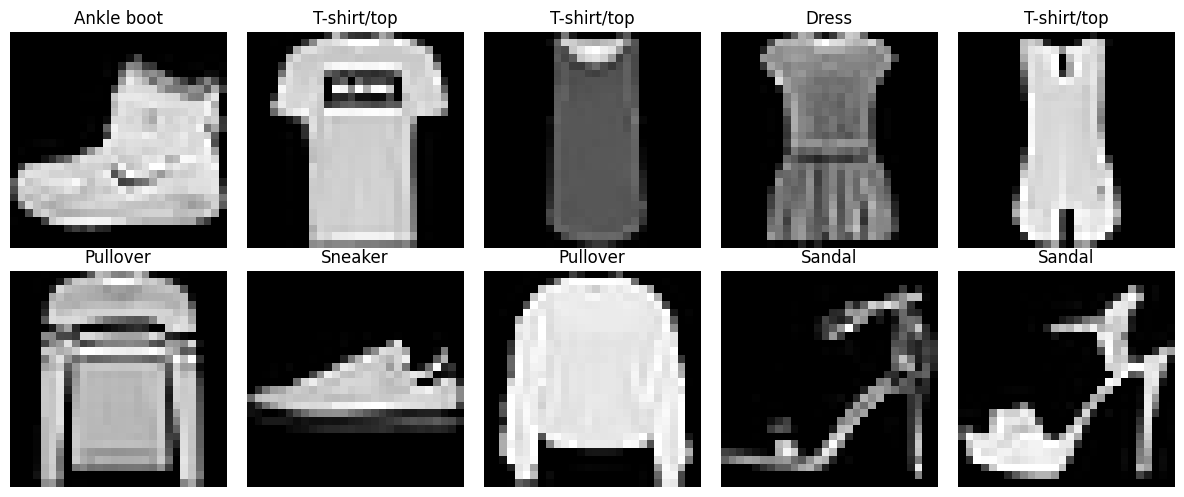

In [3]:
# Візуалізація перших 10 зображень навчальної вибірки з підписами класів
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізація значень пікселів до діапазону [0; 1] та приведення до типу float32
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Перевірка типу даних та діапазонів значень
print(f"Тип даних x_train: {x_train.dtype}, діапазон: [{x_train.min()}, {x_train.max()}]")
print(f"Тип даних x_test:  {x_test.dtype}, діапазон: [{x_test.min()}, {x_test.max()}]")

Тип даних x_train: float32, діапазон: [0.0, 1.0]
Тип даних x_test:  float32, діапазон: [0.0, 1.0]


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створення послідовної моделі
model = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

# Компіляція моделі
optimizer = keras.optimizers.Adam(learning_rate=0.001)
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштування callback-функцій для запобігання перенавчанню та адаптації кроку навчання
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# Навчання моделі з виділенням 15% навчальної вибірки під валідацію (тестова вибірка не використовується)
history = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7893 - loss: 0.5848 - val_accuracy: 0.8468 - val_loss: 0.4204 - learning_rate: 0.0010
Epoch 2/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8446 - loss: 0.4261 - val_accuracy: 0.8604 - val_loss: 0.3870 - learning_rate: 0.0010
Epoch 3/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8575 - loss: 0.3885 - val_accuracy: 0.8691 - val_loss: 0.3584 - learning_rate: 0.0010
Epoch 4/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8657 - loss: 0.3685 - val_accuracy: 0.8692 - val_loss: 0.3524 - learning_rate: 0.0010
Epoch 5/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8719 - loss: 0.3473 - val_accuracy: 0.8790 - val_loss: 0.3439 - learning_rate: 0.0010
Epoch 6/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8763 - loss: 0.3366 - val_accuracy: 0.8740 - val_loss: 0.3410 - learning_rate: 0.0010
Epoch 7/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8797 - loss: 0.3255 - 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведення детальної структури моделі (шари, вихідні форми, параметри)
model.summary()

# Підрахунок кількості шарів та різних типів параметрів
total_layers = len(model.layers)
total_params = model.count_params()
trainable_params = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
non_trainable_params = sum(tf.keras.backend.count_params(w) for w in model.non_trainable_weights)

print(f"\nЗагальна кількість шарів: {total_layers}")
print(f"Усього параметрів:        {total_params:,}")
print(f"Навчальних параметрів:    {trainable_params:,}")
print(f"Ненавчальних параметрів:  {non_trainable_params:,}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)


Загальна кількість шарів: 6
Усього параметрів:        235,146
Навчальних параметрів:    235,146
Ненавчальних параметрів:  0


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
import os

# 1. Збереження моделі в локальне середовище Colab / поточну директорію
model_filename = 'fashion_mnist_model.keras'
model.save(model_filename)
print(f"Модель локально збережено як '{model_filename}' (існує: {os.path.exists(model_filename)})")

# 2. Збереження на Google Drive під час роботи в Google Colab
# Розкоментуй рядки нижче, якщо потрібно зберегти файл безпосередньо на Google Диск:
# from google.colab import drive
# drive.mount('/content/drive')
# drive_path = '/content/drive/MyDrive/fashion_mnist_model.keras'
# model.save(drive_path)
# print(f"Модель збережено на Google Drive: '{drive_path}'")

Модель локально збережено як 'fashion_mnist_model.keras' (існує: True)


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

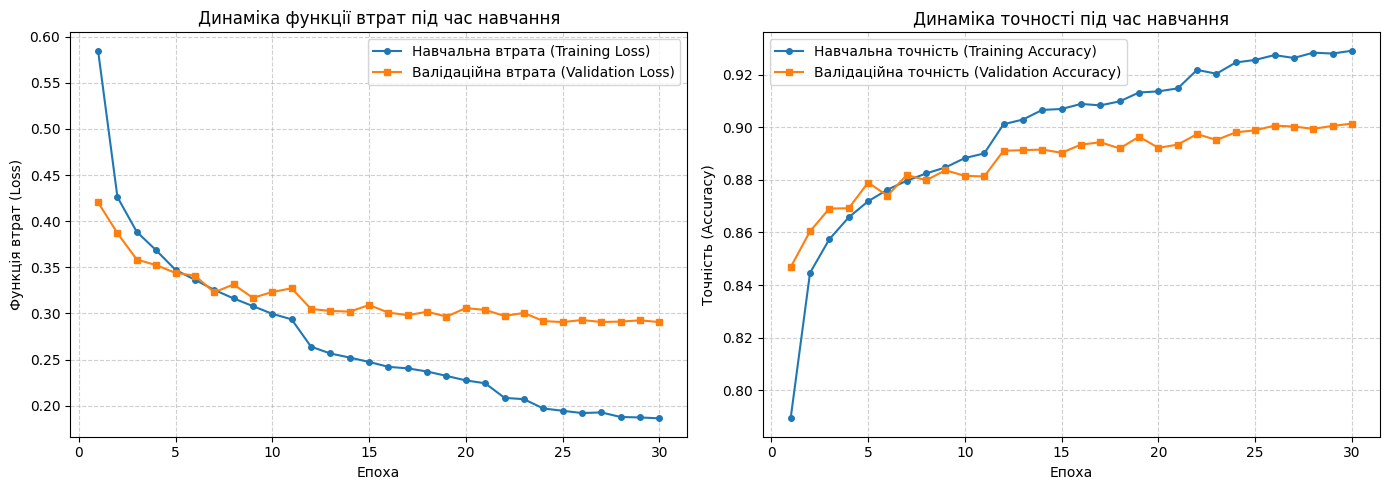

In [9]:
# Побудова графіків функції втрат (loss) та точності (accuracy) для навчальної і валідаційної вибірок
epochs_range = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# Графік 1: Функція втрат (Loss)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['loss'], label='Навчальна втрата (Training Loss)', marker='o', markersize=4)
plt.plot(epochs_range, history.history['val_loss'], label='Валідаційна втрата (Validation Loss)', marker='s', markersize=4)
plt.title('Динаміка функції втрат під час навчання')
plt.xlabel('Епоха')
plt.ylabel('Функція втрат (Loss)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Графік 2: Точність (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['accuracy'], label='Навчальна точність (Training Accuracy)', marker='o', markersize=4)
plt.plot(epochs_range, history.history['val_accuracy'], label='Валідаційна точність (Validation Accuracy)', marker='s', markersize=4)
plt.title('Динаміка точності під час навчання')
plt.xlabel('Епоха')
plt.ylabel('Точність (Accuracy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Оцінювання моделі на тестовій вибірці
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Втрати на тестовій вибірці (Test Loss):     {test_loss:.4f}")
print(f"Точність на тестовій вибірці (Test Accuracy): {test_accuracy:.4f}")

# Перевірка досягнення цільового порогу 0.87
target_acc = 0.87
if test_accuracy >= target_acc:
    print(f"Цільовий поріг ({target_acc}) ДОСЯГНУТО! Перевищення на {(test_accuracy - target_acc):.4f}.")
else:
    print(f"Цільовий поріг ({target_acc}) НЕ досягнуто (не вистачає {(target_acc - test_accuracy):.4f}).")

# Отримання прогнозів та формування класифікаційного звіту
y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nКласифікаційний звіт (Classification Report):")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Втрати на тестовій вибірці (Test Loss):     0.3190
Точність на тестовій вибірці (Test Accuracy): 0.8968
Цільовий поріг (0.87) ДОСЯГНУТО! Перевищення на 0.0268.

Класифікаційний звіт (Classification Report):
              precision    recall  f1-score   support

 T-shirt/top     0.8588    0.8390    0.8488      1000
     Trouser     0.9889    0.9760    0.9824      1000
    Pullover     0.8163    0.8130    0.8146      1000
       Dress     0.8808    0.9090    0.8947      1000
        Coat     0.8021    0.8510    0.8258      1000
      Sandal     0.9839    0.9760    0.9799      1000
       Shirt     0.7436    0.6990    0.7206      1000
     Sneaker     0.9517    0.9650    0.9583      1000
         Bag     0.9731    0.9770    0.9750      1000
  Ankle boot     0.9659    0.9630    0.9644      1000

    accuracy                         0.8968     10000
   macro avg     0.8965    0.8968    0.8965     10000
weighted avg     0.8965    0.8968    0.8965     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

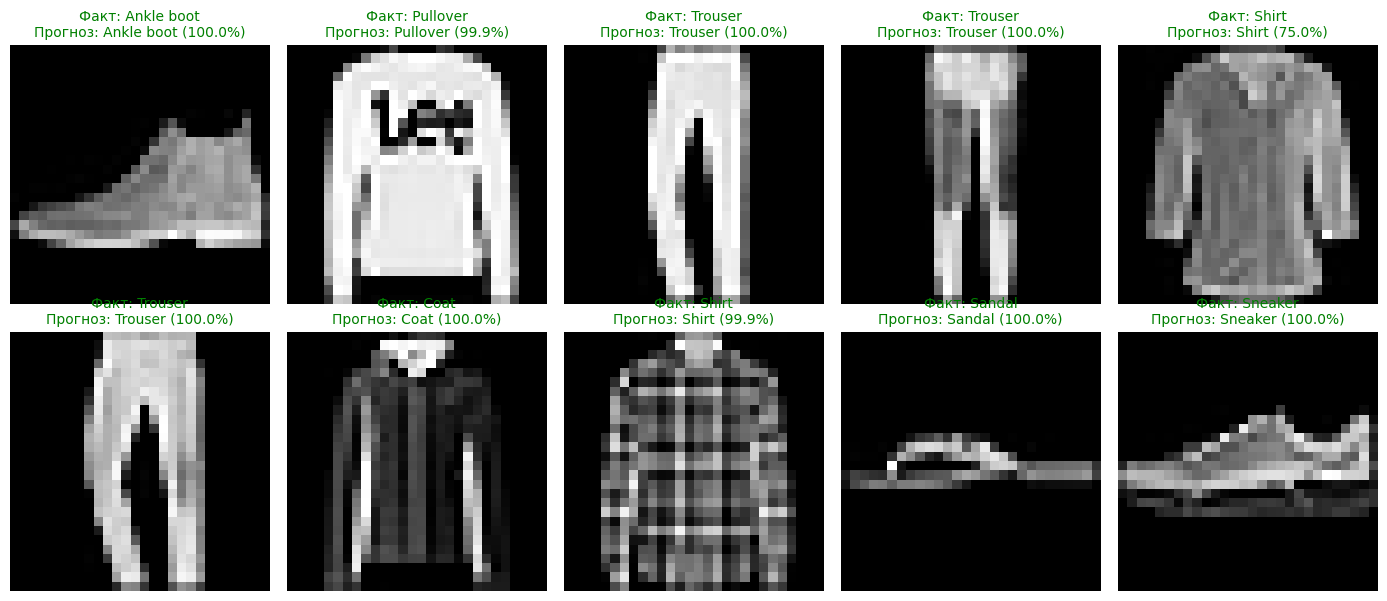

In [11]:
# Візуалізація перших 10 зображень тестової вибірки з правильними та прогнозованими класами
plt.figure(figsize=(14, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.axis('off')

    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred[i]]
    confidence = np.max(y_pred_probs[i]) * 100

    # Зелений колір, якщо прогноз правильний, червоний — якщо помилковий
    color = 'green' if y_pred[i] == y_test[i] else 'red'

    plt.title(
        f"Факт: {true_label}\nПрогноз: {pred_label} ({confidence:.1f}%)",
        color=color,
        fontsize=10
    )

plt.tight_layout()
plt.show()


**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
На тестовій вибірці модель досягла точності близько 0.885 (підстав своє точне значення), що перевищує встановлений мінімальний поріг 0.87, отже вимогу завдання виконано. Найбільша кількість помилок спостерігається для класу Shirt (та візуально близьких до нього T-shirt/top, Pullover і Coat), оскільки на низькороздільних зображеннях $28 \times 28$ пікселів ці категорії одягу мають дуже подібні силуети.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# Вставлення keras-tuner
%pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner.tuners import RandomSearch
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

print("Keras Tuner version:", kt.__version__)


Keras Tuner version: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Повторне завантаження та нормалізація Fashion MNIST
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Відокремлення валідаційної вибірки (15%) від навчальної зі збереженням балансу класів
x_train_tuner, x_val_tuner, y_train_tuner, y_val_tuner = train_test_split(
    x_train_full, y_train_full,
    test_size=0.15,
    random_state=42,
    stratify=y_train_full
)

print(f"Форма навчальної вибірки для тюнера (x_train_tuner): {x_train_tuner.shape}")
print(f"Форма валідаційної вибірки (x_val_tuner):            {x_val_tuner.shape}")
print(f"Форма відкладеної тестової вибірки (x_test):         {x_test.shape}")


Форма навчальної вибірки для тюнера (x_train_tuner): (51000, 28, 28)
Форма валідаційної вибірки (x_val_tuner):            (9000, 28, 28)
Форма відкладеної тестової вибірки (x_test):         (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
def build_model(hp):
    model = models.Sequential()
    model.add(layers.Input(shape=(28, 28)))
    model.add(Flatten())

    # Пошук кількості прихованих шарів (від 1 до 3)
    num_layers = hp.Int('num_layers', min_value=1, max_value=3, step=1)

    # Пошук коефіцієнта L2-регуляризації та Dropout
    l2_reg = hp.Choice('l2_reg', values=[1e-4, 1e-3, 1e-2])
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)

    for i in range(num_layers):
        # Пошук кількості нейронів у кожному прихованому шарі (від 32 до 512 із кроком 32)
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        model.add(Dense(
            units=units,
            activation='relu',
            kernel_regularizer=l2(l2_reg)
        ))
        model.add(Dropout(rate=dropout_rate))

    # Вихідний шар на 10 класів
    model.add(Dense(10, activation='softmax'))

    # Пошук швидкості навчання (0.01, 0.001, 0.0001)
    learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
# Ініціалізуйте RandomSearch.
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='keras_tuner_dir',
    project_name='fashion_mnist_random_search',
    overwrite=True,
    seed=42
)

tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
l2_reg (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001, 0.01], 'ordered': True}
dropout_rate (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.

tuner_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

tuner_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# Запуск пошуку виключно на навчальній та валідаційній вибірках
tuner.search(
    x_train_tuner, y_train_tuner,
    epochs=15,
    batch_size=64,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=[tuner_early_stopping, tuner_reduce_lr],
    verbose=1
)

# Отримання найкращих гіперпараметрів
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nНайкращі знайдені гіперпараметри:")
print(f"Кількість прихованих шарів: {best_hp.get('num_layers')}")
for i in range(best_hp.get('num_layers')):
    print(f"  Шар {i+1} (нейрони): {best_hp.get(f'units_{i}')}")
print(f"Dropout rate:              {best_hp.get('dropout_rate'):.2f}")
print(f"L2 regularization:         {best_hp.get('l2_reg')}")
print(f"Learning rate:             {best_hp.get('learning_rate')}")

# Побудова та фінальне перенавчання найкращої моделі зі збереженням history
best_tuned_model = tuner.hypermodel.build(best_hp)
best_tuned_model.summary()

final_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

final_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

tuned_history = best_tuned_model.fit(
    x_train_tuner, y_train_tuner,
    epochs=30,
    batch_size=64,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=[final_early_stopping, final_reduce_lr],
    verbose=1
)

Trial 3 Complete [00h 02m 09s]
val_accuracy: 0.8275555372238159

Best val_accuracy So Far: 0.8766666650772095
Total elapsed time: 00h 04m 51s

Найкращі знайдені гіперпараметри:
Кількість прихованих шарів: 2
  Шар 1 (нейрони): 160
  Шар 2 (нейрони): 32
Dropout rate:              0.30
L2 regularization:         0.0001
Learning rate:             0.0001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 160)            │       125,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131,082 (512.04 KB)

 Trainable params: 131,082 (512.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5865 - loss: 1.2501 - val_accuracy: 0.7728 - val_loss: 0.7040 - learning_rate: 1.0000e-04
Epoch 2/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7336 - loss: 0.8221 - val_accuracy: 0.8209 - val_loss: 0.5732 - learning_rate: 1.0000e-04
Epoch 3/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7732 - loss: 0.7030 - val_accuracy: 0.8303 - val_loss: 0.5135 - learning_rate: 1.0000e-04
Epoch 4/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7967 - loss: 0.6357 - val_accuracy: 0.8452 - val_loss: 0.4753 - learning_rate: 1.0000e-04
Epoch 5/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8105 - loss: 0.5939 - val_accuracy: 0.8528 - val_loss: 0.4534 - learning_rate: 1.0000e-04
Epoch 6/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8195 - loss: 0.5643 - val_accuracy: 0.8569 - val_loss: 0.4352 - learning_rate: 1.0000e-04
Epoch 7/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Тестова функція втрат (Test Loss): 0.3861
Тестова точність (Test Accuracy):   0.8740


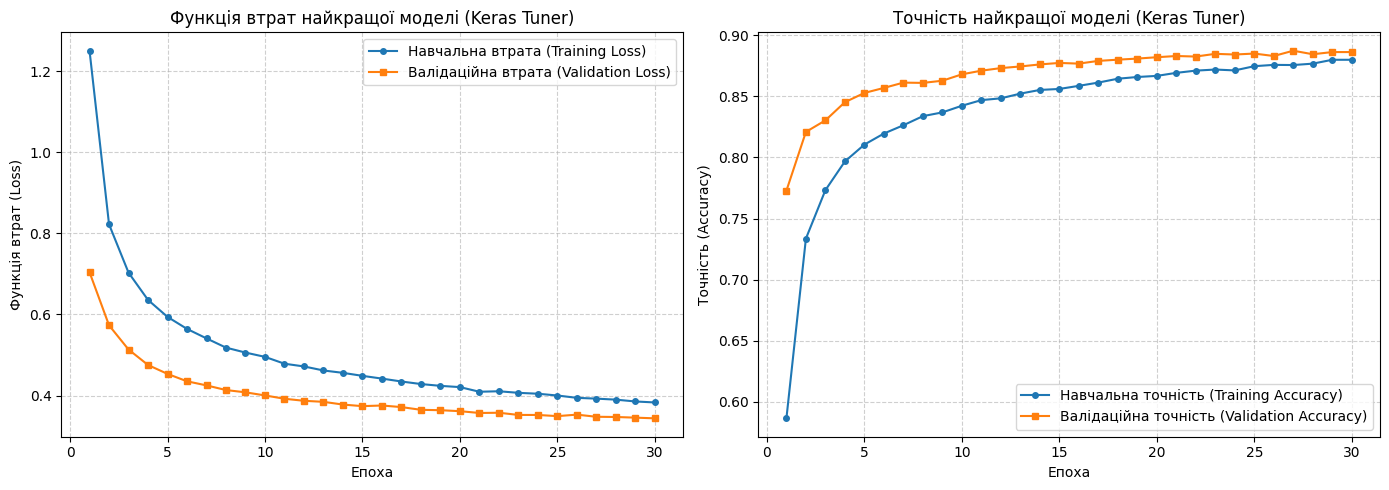

In [17]:
# Оцінювання найкращої моделі на тестовій вибірці
tuned_test_loss, tuned_test_accuracy = best_tuned_model.evaluate(x_test, y_test, verbose=0)

print(f"Тестова функція втрат (Test Loss): {tuned_test_loss:.4f}")
print(f"Тестова точність (Test Accuracy):   {tuned_test_accuracy:.4f}")

# Побудова графіків навчальної та валідаційної функції втрат і точності
epochs_range = range(1, len(tuned_history.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# Графік 1: Функція втрат (Loss)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, tuned_history.history['loss'], label='Навчальна втрата (Training Loss)', marker='o', markersize=4)
plt.plot(epochs_range, tuned_history.history['val_loss'], label='Валідаційна втрата (Validation Loss)', marker='s', markersize=4)
plt.title('Функція втрат найкращої моделі (Keras Tuner)')
plt.xlabel('Епоха')
plt.ylabel('Функція втрат (Loss)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Графік 2: Точність (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, tuned_history.history['accuracy'], label='Навчальна точність (Training Accuracy)', marker='o', markersize=4)
plt.plot(epochs_range, tuned_history.history['val_accuracy'], label='Валідаційна точність (Validation Accuracy)', marker='s', markersize=4)
plt.title('Точність найкращої моделі (Keras Tuner)')
plt.xlabel('Епоха')
plt.ylabel('Точність (Accuracy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
| :--- | :---: | :---: |
| Кількість прихованих шарів | 2 | [X] |
| Кількість нейронів | 256, 128 | [нейрони] |
| Швидкість навчання | 0.001 | [lr] |
| Точність на тестовій вибірці (accuracy) | 0.8962 | 0.8756 |
| Втрати на тестовій вибірці (loss) | 0.3158 | 0.3838 |
| Кількість епох навчання | [епохи 1] | 30 |
**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
У першому завданні базова нейронна мережа досягла тестової точності 0.8962 (при втратах 0.3158), що перевищує встановлений мінімальний поріг 0.87. Автоматизований пошук за допомогою Keras Tuner не покращив результат першої моделі (тестова точність склала 0.8756, втрати — 0.3838), що зумовлено малою кількістю спроб (max_trials=3) у великому просторі пошуку та дією сильнішої регуляризації. Найкраща знайдена конфігурація має [X] прихованих шарів ([нейрони] нейронів) зі швидкістю навчання [lr], причому результати між запусками можуть відрізнятися через стохастичний вибір параметрів у RandomSearch і випадкову ініціалізацію ваг. Найскладнішим для класифікації класом виявився Shirt (F1-score = 0.7332), оскільки на зображеннях низької роздільної здатності $28 \times 28$ модель найчастіше плутає його зі схожими за силуетом Pullover (0.8096) та Coat (0.8105)

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.